In [53]:
from pathlib import Path
import numpy as np
import pandas as pd

SEED = 42

ROOT = Path.cwd().resolve()
DATA = ROOT / "data" / "code_classification_dataset"
OUT = ROOT / "results" / "final_validation"
DATA = ROOT / "data/code_classification_dataset"
OUT = ROOT / "results/final_validation"

for folder in ["models", "predictions", "llm", "reports"]:
    (OUT / folder).mkdir(parents=True, exist_ok=True)

print("Dataset :", DATA.exists())
print("Résultats :", OUT)

Dataset : True
Résultats : /Users/zinebbentires/Documents/illuin_technology/results/final_validation


In [56]:
import json
import pandas as pd
import numpy as np
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics import f1_score
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

FOCUS = ["math", "graphs", "strings", "number theory",
         "trees", "geometry", "games", "probabilities"]

# Chargement des données
rows = []
for path in sorted(DATA.glob("sample_*.json")):
    row = json.loads(path.read_text())
    row["id"] = int(path.stem.split("_")[-1])
    rows.append(row)

df = pd.DataFrame(rows).sort_values("id").reset_index(drop=True)

TAGS = sorted(set(tag for tags in df.tags for tag in tags))
lb = MultiLabelBinarizer(classes=TAGS)
Y = lb.fit_transform(df.tags)
focus_idx = [TAGS.index(tag) for tag in FOCUS]

# Split reproductible : 3188 train / 797 val / 997 test
split_path = ROOT / "split.json"

if split_path.exists():
    split = json.loads(split_path.read_text())
else:
    splitter = MultilabelStratifiedShuffleSplit(
        n_splits=1, test_size=997, random_state=42
    )
    dev, test = next(splitter.split(df, Y[:, focus_idx]))

    splitter = MultilabelStratifiedShuffleSplit(
        n_splits=1, test_size=797, random_state=42
    )
    tr, va = next(splitter.split(df.iloc[dev], Y[dev][:, focus_idx]))

    split = {
        "fit": df.id.iloc[dev[tr]].tolist(),
        "validation": df.id.iloc[dev[va]].tolist(),
        "test": df.id.iloc[test].tolist()
    }
    split_path.write_text(json.dumps(split, indent=2))

train = df[df.id.isin(split["fit"])].copy()
val = df[df.id.isin(split["validation"])].copy()

y_train = lb.transform(train.tags)
y_val = lb.transform(val.tags)
def metrics(y, scores, threshold=0.5):
    pred = (scores >= threshold).astype(int)

    return {
        "macro_F1_8": f1_score(
            y[:, focus_idx], pred[:, focus_idx],
            average="macro", zero_division=0
        ),
        "micro_F1_8": f1_score(
            y[:, focus_idx], pred[:, focus_idx],
            average="micro", zero_division=0
        ),
        "macro_F1_37": f1_score(
            y, pred,
            average="macro", zero_division=0
        ),
        "micro_F1_37": f1_score(
            y, pred,
            average="micro", zero_division=0
        ),
        "avg_tags": pred.sum(axis=1).mean()
    }
assert len(df) == 4982
assert (len(train), len(val), len(split["test"])) == (3188, 797, 997)

print(f"Dataset: {len(df)} | Train: {len(train)} | Val: {len(val)} | Test: 997")
print(f"Tags: {len(TAGS)}")

Dataset: 4982 | Train: 3188 | Val: 797 | Test: 997
Tags: 37


### 1- Dataset exploration
We examine label prevalence, multilabel cardinality, and input lengths. This helps characterize class imbalance and motivates the choice of macro-F1 on the eight priority tags.

Problems: 3985
Tags: 37
Average tags/problem: 2.78
Median description length: 873 characters
Median code length: 682 characters


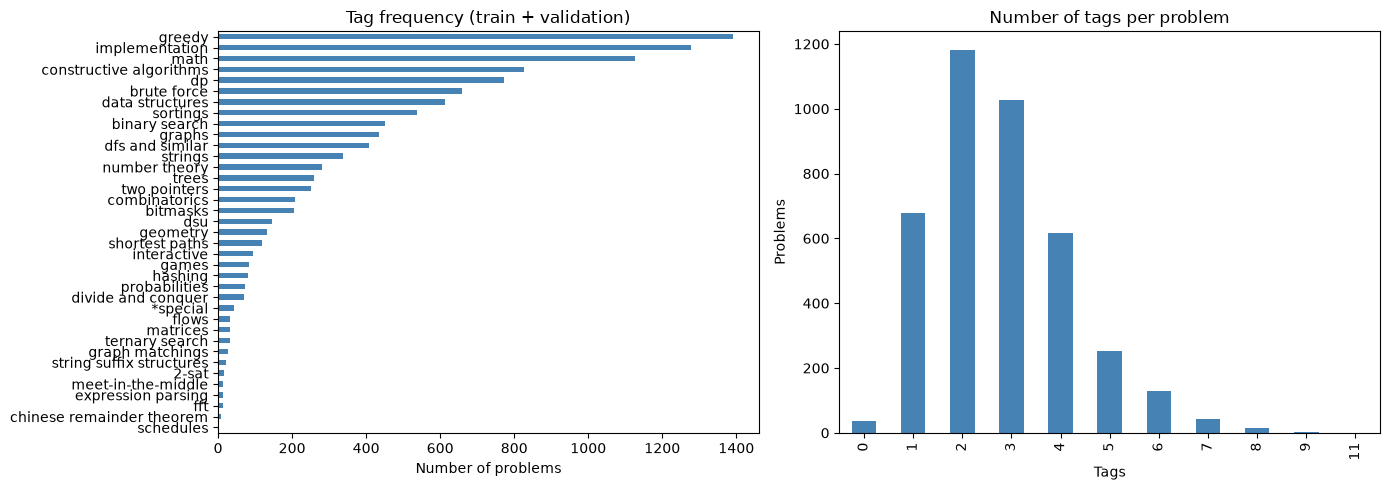

In [6]:
import matplotlib.pyplot as plt

dev = pd.concat([train, val])
Y_dev = lb.transform(dev.tags)

print(f"Problems: {len(dev)}")
print(f"Tags: {len(TAGS)}")
print(f"Average tags/problem: {Y_dev.sum(axis=1).mean():.2f}")
print(f"Median description length: {dev.prob_desc_description.str.len().median():.0f} characters")
print(f"Median code length: {dev.source_code.str.len().median():.0f} characters")

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# Distribution des 37 tags
counts = pd.Series(Y_dev.sum(axis=0), index=TAGS).sort_values()
counts.plot.barh(ax=ax[0], color="steelblue")
ax[0].set_title("Tag frequency (train + validation)")
ax[0].set_xlabel("Number of problems")

# Nombre de tags par problème
cardinality = pd.Series(Y_dev.sum(axis=1))
cardinality.value_counts().sort_index().plot.bar(ax=ax[1], color="steelblue")
ax[1].set_title("Number of tags per problem")
ax[1].set_xlabel("Tags")
ax[1].set_ylabel("Problems")

plt.tight_layout()
plt.show()

EDA — Key findings
- Strong class imbalance: greedy, implementation and math are the most frequent tags.
- Most problems have 1–4 tags, with a peak at 2.
- Some priority tags (games, probabilities, geometry) are relatively rare.
- Evaluation: macro-F1 on the 8 priority tags, micro-F1 on all 37 tags.

### ML

##### Baseline : TF-IDF

--> à revoir stop word + travailler le code spécifiquement 

In [8]:
feature_stats = []

for name, (x_train, _) in texts.items():
    vectorizer = TfidfVectorizer(
        max_features=50000,
        ngram_range=(1, 2),
        min_df=2,
        sublinear_tf=True
    )

    X = vectorizer.fit_transform(x_train)

    feature_stats.append({
        "input": name,
        "shape": X.shape,
        "density (%)": round(100 * X.nnz / (X.shape[0] * X.shape[1]), 3),
        "avg active features / problem": round(X.getnnz(axis=1).mean()),
        "mean TF-IDF (nonzero)": round(X.data.mean(), 4)
    })

    if name == "combined":
        feature_names = vectorizer.get_feature_names_out()
        mean_weights = np.asarray(X.mean(axis=0)).ravel()
        top_indices = np.argsort(mean_weights)[-15:][::-1]
        top_features = pd.DataFrame({
            "feature": feature_names[top_indices],
            "mean TF-IDF": mean_weights[top_indices]
        })

display(pd.DataFrame(feature_stats))
display(top_features)

,input,shape,density (%),avg active features / problem,mean TF-IDF (nonzero)
0,description,"(3188, 44438)",0.381,169,0.0673
1,code,"(3188, 25882)",0.354,92,0.0800
2,combined,"(3188, 50000)",0.647,324,0.0470


,feature,mean TF-IDF
0,the,0.038819
1,of,0.032451
2,in,0.028696
3,for,0.025451
4,if,0.024973
5,and,0.024670
6,to,0.024590
7,is,0.023690
8,le,0.021433
9,print,0.021039


In [57]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

texts = {
    "description": (
        train.prob_desc_description.fillna(""),
        val.prob_desc_description.fillna("")
    ),
    "code": (
        train.source_code.fillna(""),
        val.source_code.fillna("")
    ),
    "combined": (
        train.prob_desc_description.fillna("") + " " +
        train.prob_desc_input_spec.fillna("") + " " +
        train.prob_desc_output_spec.fillna("") + " " +
        train.source_code.fillna(""),

        val.prob_desc_description.fillna("") + " " +
        val.prob_desc_input_spec.fillna("") + " " +
        val.prob_desc_output_spec.fillna("") + " " +
        val.source_code.fillna("")
    )
}

results = []

for name, (x_train, x_val) in texts.items():
    tfidf = TfidfVectorizer(
        max_features=50000, ngram_range=(1, 2),
        min_df=2, sublinear_tf=True
    )

    X_train = tfidf.fit_transform(x_train)
    X_val = tfidf.transform(x_val)

    model = OneVsRestClassifier(
        LogisticRegression(C=1, solver="liblinear", max_iter=1000)
    )
    model.fit(X_train, y_train)

    probabilities = model.predict_proba(X_val)

    results.append({
        "input": name,
        **metrics(y_val, probabilities, threshold=0.15)
    })

display(pd.DataFrame(results))

,input,macro_F1_8,micro_F1_8,macro_F1_37,micro_F1_37,avg_tags
0,description,0.500276,0.521739,0.235234,0.428353,6.327478
1,code,0.359130,0.480361,0.215654,0.431328,6.061481
2,combined,0.527456,0.548944,0.260656,0.461978,6.060226


In [58]:
# Refit the combined baseline
x_train, x_val = texts["combined"]

tfidf = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_train = tfidf.fit_transform(x_train)
X_val = tfidf.transform(x_val)

model = OneVsRestClassifier(
    LogisticRegression(C=1, solver="liblinear", max_iter=1000)
)
model.fit(X_train, y_train)

val_probs = model.predict_proba(X_val)

# Threshold selection on validation
thresholds = np.arange(0.05, 0.51, 0.025)

threshold_results = pd.DataFrame([
    {"threshold": round(t, 3), **metrics(y_val, val_probs, t)}
    for t in thresholds
])

display(threshold_results.sort_values("macro_F1_8", ascending=False).head(10))

,threshold,macro_F1_8,micro_F1_8,macro_F1_37,micro_F1_37,avg_tags
3,0.125,0.551817,0.538915,0.267553,0.434718,7.343789
2,0.100,0.549124,0.506922,0.272218,0.402518,8.840652
4,0.150,0.527456,0.548944,0.260656,0.461978,6.060226
5,0.175,0.501449,0.561043,0.247571,0.478006,4.983689
1,0.075,0.496642,0.444641,0.252939,0.363448,10.614806
6,0.200,0.482580,0.569724,0.234044,0.491731,4.110414
0,0.050,0.455193,0.352117,0.228810,0.317188,13.342535
7,0.225,0.454607,0.580277,0.224819,0.500820,3.400251
8,0.250,0.418527,0.579505,0.206282,0.498649,2.853199
9,0.275,0.405727,0.569822,0.191163,0.493204,2.451694


B — TF-IDF baseline: conclusion
- Best input: description + code.
- Best threshold: 0.125, selected on validation.
- Macro-F1 (8 tags): 0.552 — our primary metric.
- Micro-F1 (37 tags): 0.435.
- Trade-off: the model predicts 7.3 tags/problem, suggesting substantial overprediction. Increasing the threshold improves micro-F1 but reduces macro-F1.

##### Sentence embeddings

In [59]:
from sentence_transformers import SentenceTransformer

# Save TF-IDF baseline for later fusion
import joblib

joblib.dump(
    {"vectorizer": tfidf, "classifier": model, "threshold": 0.125},
    OUT / "models/tfidf_baseline.joblib"
)

np.savez(
    OUT / "predictions/tfidf_validation.npz",
    ids=val.id.to_numpy(),
    probabilities=val_probs
)

# Semantic representation
def statement_text(data):
    return (
        data.prob_desc_description.fillna("") + " " +
        data.prob_desc_input_spec.fillna("") + " " +
        data.prob_desc_output_spec.fillna("")
    ).tolist()

encoder = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

X_train_emb = encoder.encode(
    statement_text(train), batch_size=32, show_progress_bar=True
)
X_val_emb = encoder.encode(
    statement_text(val), batch_size=32, show_progress_bar=True
)

print("Train embeddings:", X_train_emb.shape)
print("Validation embeddings:", X_val_emb.shape)

emb_model = OneVsRestClassifier(
    LogisticRegression(C=1, max_iter=1000)
)
emb_model.fit(X_train_emb, y_train)

emb_probs = emb_model.predict_proba(X_val_emb)

emb_results = pd.DataFrame([
    {"threshold": round(t, 3), **metrics(y_val, emb_probs, t)}
    for t in np.arange(0.05, 0.51, 0.025)
])

display(emb_results.sort_values("macro_F1_8", ascending=False).head(5))

Batches: 100%|██████████| 25/25 [00:02<00:00,  8.92it/s]


Train embeddings: (3188, 384)
Validation embeddings: (797, 384)


,threshold,macro_F1_8,micro_F1_8,macro_F1_37,micro_F1_37,avg_tags
5,0.175,0.554681,0.550101,0.245300,0.441440,5.263488
4,0.150,0.549705,0.536829,0.248161,0.428131,6.238394
3,0.125,0.541077,0.518987,0.262484,0.411561,7.440402
8,0.250,0.530147,0.562903,0.224577,0.455754,3.322459
2,0.100,0.526917,0.494759,0.263754,0.391472,8.698871


— MiniLM: conclusion
- Macro-F1: 0.555, versus 0.552 for TF-IDF.
- The difference (+0.003) is negligible: no clear improvement from semantic embeddings alone.
- MiniLM predicts fewer tags: 5.3 vs 7.3 per problem.
- Next hypothesis: lexical and semantic features may be complementary.

##### Fusion

,model,threshold,macro_F1_8,micro_F1_8,macro_F1_37,micro_F1_37,avg_tags
43,Early fusion,0.175,0.616547,0.591472,0.294197,0.492383,4.942284
98,Late fusion (TF-IDF 75%),0.125,0.570086,0.539573,0.272313,0.432644,7.537014
60,Late fusion (TF-IDF 25%),0.125,0.559717,0.524217,0.257862,0.418826,7.545797
79,Late fusion (TF-IDF 50%),0.125,0.557866,0.530519,0.260861,0.424973,7.592221
24,MiniLM,0.175,0.554681,0.550101,0.245300,0.441440,5.263488
3,TF-IDF,0.125,0.551817,0.538915,0.267553,0.434718,7.343789


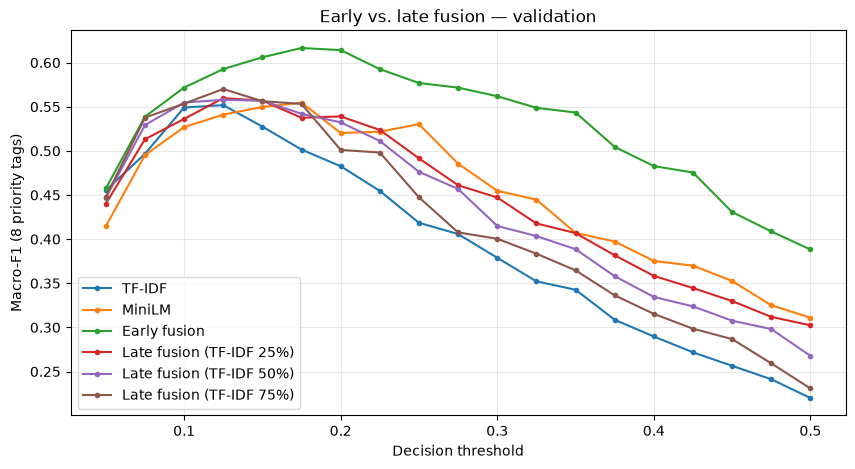

In [60]:
from scipy.sparse import hstack, csr_matrix
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt

thresholds = np.arange(0.05, 0.51, 0.025)

# 1. Early fusion: concatenate features before classification
X_train_early = hstack([
    X_train,
    csr_matrix(normalize(X_train_emb))
]).tocsr()

X_val_early = hstack([
    X_val,
    csr_matrix(normalize(X_val_emb))
]).tocsr()

early_model = OneVsRestClassifier(
    LogisticRegression(C=1, solver="liblinear", max_iter=1000)
)
early_model.fit(X_train_early, y_train)
early_probs = early_model.predict_proba(X_val_early)

# 2. Late fusion: combine probabilities from separate models
alphas = [0.25, 0.5, 0.75]
late_predictions = {
    f"Late fusion (TF-IDF {a:.0%})":
        a * val_probs + (1 - a) * emb_probs
    for a in alphas
}

# 3. Compare all models across decision thresholds
predictions = {
    "TF-IDF": val_probs,
    "MiniLM": emb_probs,
    "Early fusion": early_probs,
    **late_predictions
}

rows = []

for name, probs in predictions.items():
    for t in thresholds:
        rows.append({
            "model": name,
            "threshold": round(float(t), 3),
            **metrics(y_val, probs, t)
        })

comparison = pd.DataFrame(rows)

best = (
    comparison.sort_values("macro_F1_8", ascending=False)
    .drop_duplicates("model")
    .sort_values("macro_F1_8", ascending=False)
)

display(best)

# 4. Plot macro-F1 against threshold
plt.figure(figsize=(10, 5))

for name, group in comparison.groupby("model", sort=False):
    plt.plot(
        group.threshold,
        group.macro_F1_8,
        marker=".",
        label=name
    )

plt.xlabel("Decision threshold")
plt.ylabel("Macro-F1 (8 priority tags)")
plt.title("Early vs. late fusion — validation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

###### Early fusion tuning

In [61]:
from itertools import product
import sys

if not sys.warnoptions:
    import warnings
    warnings.simplefilter("ignore")
Xtr = X_train_early
Xva = X_val_early

grid = product(
    ["l1", "l2"],
    [0.1, 1, 10, 100]
)

reg_results = []

for penalty, C in grid:
    clf = OneVsRestClassifier(
        LogisticRegression(
            penalty=penalty,
            C=C,
            solver="liblinear",
            max_iter=1000
        )
    )

    clf.fit(Xtr, y_train)
    probs = clf.predict_proba(Xva)

    for threshold in np.arange(0.10, 0.31, 0.025):
        reg_results.append({
            "penalty": penalty,
            "C": C,
            "threshold": round(float(threshold), 3),
            **metrics(y_val, probs, threshold)
        })

reg_df = pd.DataFrame(reg_results)

best_reg = (
    reg_df.sort_values("macro_F1_8", ascending=False)
    .drop_duplicates(["penalty", "C"])
    .sort_values("macro_F1_8", ascending=False)
)

display(best_reg)

,penalty,C,threshold,macro_F1_8,micro_F1_8,macro_F1_37,micro_F1_37,avg_tags
60,l2,10.0,0.250,0.648273,0.628128,0.317587,0.518486,2.915935
63,l2,100.0,0.100,0.647961,0.624712,0.328456,0.509542,3.856964
23,l1,10.0,0.225,0.624577,0.585045,0.322988,0.480657,3.542033
48,l2,1.0,0.175,0.616547,0.591472,0.294197,0.492383,4.942284
30,l1,100.0,0.175,0.600268,0.564726,0.313422,0.472950,3.219573
13,l1,1.0,0.200,0.585929,0.569176,0.298353,0.496608,4.311167
38,l2,0.1,0.150,0.382141,0.501211,0.180997,0.406028,7.189460
1,l1,0.1,0.125,0.159013,0.387461,0.099042,0.338451,8.314931


Regularization: 
- L2 consistently outperforms L1, suggesting that retaining distributed features is more effective than sparse feature selection.
- Strong regularization (C=0.1) substantially hurts performance.
- Selected model: L2, C=10, threshold 0.25.
- Macro-F1: 0.648, micro-F1: 0.518, with 2.9 predicted tags/problem.
- We retain unweighted early fusion for simplicity. The weighted variant reached 0.664, but adds another hyperparameter.

In [62]:
import joblib

# Selected early-fusion classifier
final_ml = OneVsRestClassifier(
    LogisticRegression(
        penalty="l2",
        C=10,
        solver="liblinear",
        max_iter=1000
    )
)

final_ml.fit(X_train_early, y_train)
ml_probs = final_ml.predict_proba(X_val_early)

print(metrics(y_val, ml_probs, threshold=0.25))

joblib.dump(
    {
        "tfidf": tfidf,
        "classifier": final_ml,
        "embedding_model": "sentence-transformers/all-MiniLM-L6-v2",
        "threshold": 0.25,
        "tags": TAGS
    },
    OUT / "models/early_fusion.joblib"
)

np.savez(
    OUT / "predictions/early_fusion_validation.npz",
    ids=val.id.to_numpy(),
    probabilities=ml_probs,
    labels=y_val
)

{'macro_F1_8': 0.6482728192808838, 'micro_F1_8': 0.6281276962899051, 'macro_F1_37': 0.3175873275126525, 'micro_F1_37': 0.5184855233853006, 'avg_tags': np.float64(2.915934755332497)}


### LLM

##### Gemini Zero Shot

In [63]:
import os
import json
import asyncio
from tqdm.auto import tqdm
from google import genai
from google.genai import types

cfg = json.loads((ROOT / "configs/gemini_zero_shot.json").read_text())
client = genai.Client(api_key=os.environ["GEMINI_API_KEY"])

output = OUT / "llm/zero_shot.jsonl"

api_config = types.GenerateContentConfig(
    temperature=cfg["temperature"],
    response_mime_type="application/json",
    response_schema=cfg["response_schema"]
)

def make_prompt(row):
    return f"""
{cfg['instruction']}

Allowed tags: {", ".join(cfg['allowed_tags'])}

Problem:
{row['prob_desc_description']}

Input:
{row['prob_desc_input_spec']}

Output:
{row['prob_desc_output_spec']}

Python solution:
{row['source_code']}
"""

async def predict(row):
    for attempt in range(3):
        try:
            response = await client.aio.models.generate_content(
                model=cfg["model"],
                contents=make_prompt(row),
                config=api_config
            )

            tags = json.loads(response.text)["tags"]
            if not isinstance(tags, list) or any(t not in TAGS for t in tags):
                raise ValueError(f"Invalid tags: {tags}")

            return {"id": int(row["id"]), "tags": tags, "ok": True}

        except Exception as e:
            if attempt == 2:
                return {"id": int(row["id"]), "ok": False, "error": str(e)}
            await asyncio.sleep(2 ** attempt)


async def run_zero_shot(load_from_cache=True):
    rows = val.to_dict("records")

    # Load existing predictions
    cached = {}
    if load_from_cache and output.exists():
        with output.open() as f:
            for line in f:
                if line.strip():
                    r = json.loads(line)
                    if r.get("ok") and isinstance(r.get("tags"), list):
                        cached[int(r["id"])] = r

    missing = [row for row in rows if int(row["id"]) not in cached]

    print(f"Cached: {len(rows) - len(missing)} | Missing: {len(missing)}")

    if not missing:
        print("All predictions loaded from cache. No API calls.")
        return

    semaphore = asyncio.Semaphore(5)

    async def worker(row):
        async with semaphore:
            return await predict(row)

    tasks = [asyncio.create_task(worker(row)) for row in missing]

    # Append results instead of overwriting the cache
    with output.open("a") as f:
        for task in tqdm(asyncio.as_completed(tasks), total=len(tasks)):
            result = await task
            f.write(json.dumps(result) + "\n")
            f.flush()

    print("Inference completed.")
    

await run_zero_shot(load_from_cache=True)

Cached: 797 | Missing: 0
All predictions loaded from cache. No API calls.


In [64]:
from sklearn.metrics import precision_recall_fscore_support

# Read predictions produced by the current Gemini run
records = [
    json.loads(line)
    for line in output.read_text().splitlines()
    if line.strip()
]

results = pd.DataFrame(records)

success = results[results["ok"]].drop_duplicates("id", keep="last")
failures = results[~results["ok"]]

print(f"Successful: {len(success)} / {len(val)}")
print(f"Failed calls: {len(failures)}")
print(f"Missing IDs: {len(set(val.id) - set(success.id))}")

if len(success) != len(val) or set(success.id) != set(val.id):
    print("Incomplete validation coverage — inspect failures before comparing scores.")

else:
    # Align Gemini predictions with the existing validation split
    gemini_tags = success.set_index("id").loc[val.id, "tags"].tolist()
    gemini_pred = lb.transform(gemini_tags)

    comparison = pd.DataFrame([
        {"model": "Early fusion (L2, C=10)",
         **metrics(y_val, ml_probs, threshold=0.25)},
        {"model": "Gemini zero-shot",
         **metrics(y_val, gemini_pred, threshold=0.5)}
    ]).set_index("model")

    display(comparison.round(3))

    # Per-tag F1 on the 8 focus tags
    _, _, ml_f1, _ = precision_recall_fscore_support(
        y_val[:, focus_idx],
        (ml_probs[:, focus_idx] >= 0.25).astype(int),
        average=None,
        zero_division=0
    )

    _, _, gemini_f1, _ = precision_recall_fscore_support(
        y_val[:, focus_idx],
        gemini_pred[:, focus_idx],
        average=None,
        zero_division=0
    )

    per_tag = pd.DataFrame({
        "tag": FOCUS,
        "ML_F1": ml_f1,
        "Gemini_F1": gemini_f1,
        "difference": gemini_f1 - ml_f1
    }).set_index("tag")

    display(per_tag.round(3))

    np.savez(
        OUT / "predictions/gemini_zero_shot_validation.npz",
        ids=val.id.to_numpy(),
        predictions=gemini_pred
    )

Successful: 797 / 797
Failed calls: 0
Missing IDs: 0


,macro_F1_8,micro_F1_8,macro_F1_37,micro_F1_37,avg_tags
model,,,,,
"Early fusion (L2, C=10)",0.648,0.628,0.318,0.518,2.916
Gemini zero-shot,0.847,0.813,0.676,0.772,2.604


,ML_F1,Gemini_F1,difference
tag,,,
math,0.618,0.772,0.154
graphs,0.591,0.807,0.216
strings,0.699,0.831,0.132
number theory,0.465,0.818,0.354
trees,0.731,0.887,0.156
geometry,0.692,0.893,0.201
games,0.750,0.889,0.139
probabilities,0.640,0.882,0.242


#### Few shot Learning

In [31]:
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

sampler = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.10,
    random_state=SEED
)

_, selected_idx = next(
    sampler.split(val, y_val[:, focus_idx])
)

few_val = val.iloc[selected_idx].sort_values("id").copy()
few_y = lb.transform(few_val.tags)

coverage = pd.DataFrame({
    "tag": FOCUS,
    "full_validation": y_val[:, focus_idx].sum(axis=0),
    "few_shot_subset": few_y[:, focus_idx].sum(axis=0)
})

display(coverage)
print(f"Selected: {len(few_val)} / {len(val)}")

(OUT / "reports/few_shot_ids.json").write_text(
    json.dumps(few_val.id.astype(int).tolist(), indent=2)
)

,tag,full_validation,few_shot_subset
0,math,225,23
1,graphs,87,9
2,strings,68,7
3,number theory,56,6
4,trees,52,5
5,geometry,27,3
6,games,17,2
7,probabilities,15,2


Selected: 80 / 797


623

In [65]:
import time

# Same 3 labeled training examples for every validation problem
fixed_examples = train.sample(n=3, random_state=SEED)

def format_example(row):
    return (
        f"Problem: {str(row['prob_desc_description'])[:500]}\n"
        f"Tags: {json.dumps(row['tags'])}"
    )

demos = "\n\n".join(
    format_example(row) for row in fixed_examples.to_dict("records")
)

def fixed_prompt(row):
    return make_prompt(row).replace(
        "\n\nProblem:",
        f"\n\nLabeled training examples:\n{demos}\n\nProblem:",
        1
    )

# Save reproducible configuration
fixed_cfg = {
    **cfg,
    "experiment": "fixed_few_shot",
    "n_shots": 3,
    "example_ids": fixed_examples.id.astype(int).tolist(),
    "max_example_chars": 500,
    "validation_ids": few_val.id.astype(int).tolist()
}

(ROOT / "configs/gemini_few_fixed.json").write_text(
    json.dumps(fixed_cfg, indent=2)
)

async def predict_fixed(row):
    for attempt in range(3):
        start = time.perf_counter()

        try:
            response = await client.aio.models.generate_content(
                model=cfg["model"],
                contents=fixed_prompt(row),
                config=api_config
            )

            tags = json.loads(response.text)["tags"]
            if not isinstance(tags, list) or any(t not in TAGS for t in tags):
                raise ValueError(f"Invalid tags: {tags}")

            usage = response.usage_metadata

            return {
                "id": int(row["id"]),
                "tags": tags,
                "ok": True,
                "latency_s": round(time.perf_counter() - start, 2),
                "input_tokens": getattr(usage, "prompt_token_count", None),
                "output_tokens": getattr(usage, "candidates_token_count", None),
                "thinking_tokens": getattr(usage, "thoughts_token_count", None),
                "total_tokens": getattr(usage, "total_token_count", None)
            }

        except Exception as e:
            if attempt == 2:
                return {
                    "id": int(row["id"]),
                    "ok": False,
                    "error": str(e)
                }
            await asyncio.sleep(2 ** attempt)

async def run_fixed(load_from_cache=True):
    output_fixed = OUT / "llm/fixed_few_shot.jsonl"
    rows = few_val.to_dict("records")

    cached = {}
    if load_from_cache and output_fixed.exists():
        with output_fixed.open() as f:
            for line in f:
                if line.strip():
                    r = json.loads(line)
                    if r.get("ok") and isinstance(r.get("tags"), list):
                        cached[int(r["id"])] = r

    missing = [row for row in rows if int(row["id"]) not in cached]

    print(f"Cached: {len(rows) - len(missing)} | Missing: {len(missing)}")

    if not missing:
        print("All predictions loaded from cache. No API calls.")
        return

    semaphore = asyncio.Semaphore(5)

    async def worker(row):
        async with semaphore:
            return await predict_fixed(row)

    tasks = [worker(row) for row in missing]

    # Append new predictions without overwriting existing ones
    output_fixed.parent.mkdir(parents=True, exist_ok=True)

    with output_fixed.open("a") as f:
        for task in tqdm(asyncio.as_completed(tasks), total=len(tasks)):
            result = await task
            f.write(json.dumps(result) + "\n")
            f.flush()

    print("Fixed few-shot completed.")

print("Validation problems:", len(few_val))
print("Training demonstrations:", fixed_cfg["example_ids"])
print("Prompt preview:\n", fixed_prompt(few_val.iloc[0])[:1500])
await run_fixed(load_from_cache=True)

Validation problems: 80
Training demonstrations: [1582, 1539, 1220]
Prompt preview:
 
You are classifying competitive programming problems. Identify all relevant Codeforces algorithmic tags using the problem statement and Python solution. Select only tags from the allowed list. Return only the predicted tags as JSON, without explanations.

Allowed tags: *special, 2-sat, binary search, bitmasks, brute force, chinese remainder theorem, combinatorics, constructive algorithms, data structures, dfs and similar, divide and conquer, dp, dsu, expression parsing, fft, flows, games, geometry, graph matchings, graphs, greedy, hashing, implementation, interactive, math, matrices, meet-in-the-middle, number theory, probabilities, schedules, shortest paths, sortings, string suffix structures, strings, ternary search, trees, two pointers

Labeled training examples:
Problem: Word $$$s$$$ of length $$$n$$$ is called $$$k$$$-complete if   $$$s$$$ is a palindrome, i.e. $$$s_i=s_{n+1-i}$$$ for all $$$1 \l

In [66]:
# Fixed few-shot predictions
fixed_results = pd.DataFrame([
    json.loads(line)
    for line in (OUT / "llm/fixed_few_shot.jsonl").read_text().splitlines()
    if line.strip()
])

fixed_ok = fixed_results[fixed_results.ok].drop_duplicates("id").set_index("id")

print(f"Successful: {len(fixed_ok)} / {len(few_val)}")
print(f"Missing IDs: {len(set(few_val.id) - set(fixed_ok.index))}")

if set(few_val.id) == set(fixed_ok.index):
    # Align both methods on the same validation examples
    few_ids = few_val.id.to_numpy()
    few_y = lb.transform(few_val.tags)

    fixed_pred = lb.transform(fixed_ok.loc[few_ids, "tags"].tolist())

    zero_subset = success.set_index("id").loc[few_ids, "tags"].tolist() \
        if "id" in success.columns else success.loc[few_ids, "tags"].tolist()
    zero_pred = lb.transform(zero_subset)

    comparison_few = pd.DataFrame([
        {"model": "Gemini zero-shot", **metrics(few_y, zero_pred)},
        {"model": "Gemini fixed few-shot", **metrics(few_y, fixed_pred)}
    ]).set_index("model")

    display(comparison_few.round(3))

    print(
        "Mean API latency:",
        round(fixed_ok.latency_s.mean(), 2), "s"
    )
    print(
        "Total recorded tokens:",
        fixed_ok.total_tokens.sum()
    )

Successful: 80 / 80
Missing IDs: 0


,macro_F1_8,micro_F1_8,macro_F1_37,micro_F1_37,avg_tags
model,,,,,
Gemini zero-shot,0.866,0.838,0.580,0.791,2.638
Gemini fixed few-shot,0.855,0.847,0.533,0.795,2.675


Mean API latency: 8.6 s
Total recorded tokens: 166944


**Key findings**
- Fixed few-shot shows no meaningful improvement over zero-shot on the selected validation subset.
- Adding 3 labeled training examples increases prompt length without a clear performance benefit.
- Next, we test whether retrieving semantically similar examples is more effective than using fixed demonstrations.
- Results remain exploratory given the limited evaluation subset.

#### Retrieval few shot

**Key findings**
- Gemini zero-shot substantially outperforms the tuned early-fusion baseline: 0.847 vs 0.648 macro-F1.
- Performance improves across all 8 priority tags, particularly number theory, probabilities and graphs.
- Gemini also achieves higher micro-F1 across all 37 tags (0.772 vs 0.518).
- All 797 validation requests completed successfully, with no API failures.

In [67]:
import time
from sklearn.preprocessing import normalize

# Reuse previously computed MiniLM embeddings
train_vectors = normalize(X_train_emb)
val_vectors = normalize(X_val_emb)

# Align few_val with X_val_emb (which follows val order)
few_positions = np.flatnonzero(val.id.isin(few_val.id))
similarities = val_vectors[few_positions] @ train_vectors.T

# Top-3 nearest training examples for each validation problem
nearest_idx = np.argsort(-similarities, axis=1)[:, :3]

retrieved_ids = {
    int(val.iloc[pos].id): train.iloc[neighbors].id.astype(int).tolist()
    for pos, neighbors in zip(few_positions, nearest_idx)
}

def retrieval_prompt(row):
    examples = train.set_index("id").loc[retrieved_ids[int(row["id"])]]
    demos = "\n\n".join(
        format_example(ex) for ex in examples.to_dict("records")
    )
    return make_prompt(row).replace(
        "\n\nProblem:",
        f"\n\nLabeled training examples:\n{demos}\n\nProblem:",
        1
    )

# Save configuration and selected training examples
retrieval_cfg = {
    **cfg,
    "experiment": "retrieval_few_shot",
    "n_shots": 3,
    "retrieval": "cosine_similarity_MiniLM",
    "max_example_chars": 500,
    "validation_ids": few_val.id.astype(int).tolist(),
    "retrieved_training_ids": retrieved_ids
}

(ROOT / "configs/gemini_few_retrieval.json").write_text(
    json.dumps(retrieval_cfg, indent=2)
)

async def predict_retrieval(row):
    for attempt in range(3):
        start = time.perf_counter()

        try:
            response = await client.aio.models.generate_content(
                model=cfg["model"],
                contents=retrieval_prompt(row),
                config=api_config
            )

            tags = json.loads(response.text)["tags"]
            if not isinstance(tags, list) or any(t not in TAGS for t in tags):
                raise ValueError(f"Invalid tags: {tags}")

            usage = response.usage_metadata

            return {
                "id": int(row["id"]),
                "tags": tags,
                "ok": True,
                "latency_s": round(time.perf_counter() - start, 2),
                "input_tokens": getattr(usage, "prompt_token_count", None),
                "output_tokens": getattr(usage, "candidates_token_count", None),
                "thinking_tokens": getattr(usage, "thoughts_token_count", None),
                "total_tokens": getattr(usage, "total_token_count", None)
            }

        except Exception as e:
            if attempt == 2:
                return {
                    "id": int(row["id"]),
                    "ok": False,
                    "error": str(e)
                }
            await asyncio.sleep(2 ** attempt)

output_retrieval = OUT / "llm/retrieval_few_shot.jsonl"

saved = [
    json.loads(line)
    for line in output_retrieval.read_text().splitlines()
    if line.strip()
] if output_retrieval.exists() else []

completed = {r["id"] for r in saved if r.get("ok")}

print(f"Saved: {len(completed)} / {len(few_val)}")
print(f"Remaining: {len(few_val) - len(completed)}")

async def run_retrieval():
    remaining = few_val[~few_val.id.isin(completed)].to_dict("records")

    semaphore = asyncio.Semaphore(5)

    async def worker(row):
        async with semaphore:
            return await predict_retrieval(row)

    tasks = [worker(row) for row in remaining]

    with output_retrieval.open("a") as f:  # Append, never overwrite
        for task in tqdm(asyncio.as_completed(tasks), total=len(tasks)):
            result = await task
            f.write(json.dumps(result) + "\n")
            f.flush()

    print("Retrieval few-shot completed.")

await run_retrieval()

Saved: 80 / 80
Remaining: 0


0it [00:00, ?it/s]

Retrieval few-shot completed.


#### Comparison

In [68]:
# Read retrieval predictions
retrieval_results = pd.DataFrame([
    json.loads(line)
    for line in output_retrieval.read_text().splitlines()
    if line.strip()
])

retrieval_ok = (
    retrieval_results[retrieval_results.ok]
    .drop_duplicates("id", keep="last")
    .set_index("id")
)

few_ids = few_val.id.to_numpy()

print(f"Retrieval coverage: {len(set(few_ids) & set(retrieval_ok.index))}/{len(few_ids)}")

if not set(few_ids).issubset(retrieval_ok.index):
    print("Some predictions are missing. Resume retrieval before evaluating.")

else:
    few_y = lb.transform(few_val.tags)

    retrieval_pred = lb.transform(
        retrieval_ok.loc[few_ids, "tags"].tolist()
    )

    comparison_prompting = pd.DataFrame([
        {"model": "Zero-shot", **metrics(few_y, zero_pred)},
        {"model": "Fixed few-shot", **metrics(few_y, fixed_pred)},
        {"model": "Retrieval few-shot", **metrics(few_y, retrieval_pred)}
    ]).set_index("model")

    display(comparison_prompting.round(3))

    # Resource usage (recorded for few-shot experiments)
    usage_comparison = pd.DataFrame({
        "model": ["Fixed few-shot", "Retrieval few-shot"],
        "mean_latency_s": [
            fixed_ok.loc[few_ids, "latency_s"].mean(),
            retrieval_ok.loc[few_ids, "latency_s"].mean()
        ],
        "mean_input_tokens": [
            fixed_ok.loc[few_ids, "input_tokens"].mean(),
            retrieval_ok.loc[few_ids, "input_tokens"].mean()
        ],
        "total_tokens": [
            fixed_ok.loc[few_ids, "total_tokens"].sum(),
            retrieval_ok.loc[few_ids, "total_tokens"].sum()
        ]
    }).set_index("model")

    display(usage_comparison.round(1))

Retrieval coverage: 80/80


,macro_F1_8,micro_F1_8,macro_F1_37,micro_F1_37,avg_tags
model,,,,,
Zero-shot,0.866,0.838,0.580,0.791,2.638
Fixed few-shot,0.855,0.847,0.533,0.795,2.675
Retrieval few-shot,0.849,0.814,0.596,0.782,2.638


,mean_latency_s,mean_input_tokens,total_tokens
model,,,
Fixed few-shot,8.6,1416.8,166944
Retrieval few-shot,9.1,1376.6,173408


**Key findings**
- Zero-shot achieves the highest macro-F1 (0.866) on the 80-problem subset.
- Neither fixed nor retrieval few-shot improves the primary metric.
- Retrieval-based demonstrations do not outperform fixed examples.
- Few-shot prompting introduces additional token usage and latency without a measurable benefit in this experiment.
- We retain zero-shot as the preferred LLM strategy.

### TEST

Gemini

In [69]:
import asyncio
import time
import json
from tqdm.auto import tqdm

test = df[df.id.isin(split["test"])].copy()
test_output = OUT / "llm/zero_shot_test.jsonl"

def load_test_cache():
    if not test_output.exists():
        return []
    return [
        json.loads(line)
        for line in test_output.read_text().splitlines()
        if line.strip()
    ]

async def predict_test(row):
    for attempt in range(3):
        start = time.perf_counter()
        try:
            response = await client.aio.models.generate_content(
                model=cfg["model"],
                contents=make_prompt(row),
                config=api_config
            )

            tags = json.loads(response.text)["tags"]
            if not isinstance(tags, list) or any(t not in TAGS for t in tags):
                raise ValueError(f"Invalid tags: {tags}")

            usage = response.usage_metadata

            return {
                "id": int(row["id"]),
                "tags": tags,
                "ok": True,
                "latency_s": time.perf_counter() - start,
                "input_tokens": getattr(usage, "prompt_token_count", None),
                "output_tokens": getattr(usage, "candidates_token_count", None),
                "thinking_tokens": getattr(usage, "thoughts_token_count", None),
                "total_tokens": getattr(usage, "total_token_count", None)
            }

        except Exception as e:
            if attempt == 2:
                return {"id": int(row["id"]), "ok": False, "error": str(e)}
            await asyncio.sleep(2 ** attempt)


saved = load_test_cache()
completed = {r["id"] for r in saved if r.get("ok")}
remaining = test[~test.id.isin(completed)].to_dict("records")

print(f"Cached: {len(completed)}/{len(test)}")
print(f"Remaining: {len(remaining)}")

async def run_test():
    semaphore = asyncio.Semaphore(5)

    async def worker(row):
        async with semaphore:
            return await predict_test(row)

    tasks = [worker(row) for row in remaining]

    with test_output.open("a") as f:
        for task in tqdm(asyncio.as_completed(tasks), total=len(tasks)):
            result = await task
            f.write(json.dumps(result) + "\n")
            f.flush()

await run_test()

test_results = pd.DataFrame(load_test_cache())
test_ok = test_results[test_results.ok].drop_duplicates("id").set_index("id")

print(f"Test coverage: {len(set(test.id) & set(test_ok.index))}/{len(test)}")

if set(test.id).issubset(test_ok.index):
    gemini_test_pred = lb.transform(test_ok.loc[test.id, "tags"].tolist())

    display(
        test_ok.loc[test.id, [
            "latency_s", "input_tokens", "output_tokens",
            "thinking_tokens", "total_tokens"
        ]].agg(["mean", "median", "sum"]).round(2)
    )

    y_test = lb.transform(test.tags)

    print("Gemini — Test")
    print(metrics(y_test, gemini_test_pred))

Cached: 997/997
Remaining: 0


0it [00:00, ?it/s]

Test coverage: 997/997


,latency_s,input_tokens,output_tokens,thinking_tokens,total_tokens
mean,7.13,1097.82,23.22,573.61,1692.92
median,5.61,934.00,23.00,394.00,1394.00
sum,7113.00,1094523.00,23151.00,570172.00,1687846.00


Gemini — Test
{'macro_F1_8': 0.8268415142998629, 'micro_F1_8': 0.8158640226628895, 'macro_F1_37': 0.6783544597032811, 'micro_F1_37': 0.7733284349742836, 'avg_tags': np.float64(2.60481444332999)}


ML

In [54]:
import joblib
from scipy.sparse import hstack, csr_matrix
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression

dev = pd.concat([train, val]).sort_values("id").copy()
test = df[df.id.isin(split["test"])].sort_values("id").copy()

def tfidf_text(data):
    return (
        data.prob_desc_description.fillna("") + " " +
        data.prob_desc_input_spec.fillna("") + " " +
        data.prob_desc_output_spec.fillna("") + " " +
        data.source_code.fillna("")
    )



# Verify original preprocessing before refitting
X_check = tfidf.transform(tfidf_text(val))
diff = X_check - X_val
print("Original TF-IDF reproduced:", diff.nnz == 0)
assert np.allclose(X_check.toarray(), X_val.toarray(), atol=1e-6), \
    "Original TF-IDF preprocessing mismatch"

# Refit TF-IDF on train + validation
tfidf_final = TfidfVectorizer(
    max_features=50000,
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True
)

X_dev_tf = tfidf_final.fit_transform(tfidf_text(dev))
X_test_tf = tfidf_final.transform(tfidf_text(test))

# Reuse existing MiniLM embeddings, aligned by ID
emb_lookup = {
    **dict(zip(train.id, X_train_emb)),
    **dict(zip(val.id, X_val_emb))
}

X_dev_emb = np.vstack([emb_lookup[i] for i in dev.id])
X_test_emb = encoder.encode(
    statement_text(test),
    batch_size=32,
    show_progress_bar=True
)

X_dev = hstack([
    X_dev_tf,
    csr_matrix(normalize(X_dev_emb))
]).tocsr()

X_test = hstack([
    X_test_tf,
    csr_matrix(normalize(X_test_emb))
]).tocsr()

# Fit final ML model
ml_final = OneVsRestClassifier(
    LogisticRegression(
        C=10, penalty="l2",
        solver="liblinear", max_iter=1000
    )
)

ml_final.fit(X_dev, lb.transform(dev.tags))

ml_test_probs = ml_final.predict_proba(X_test)
ml_test_pred = (ml_test_probs >= 0.25).astype(int)

# Save model and predictions
joblib.dump({
    "model": ml_final,
    "tfidf": tfidf_final,
    "encoder": "sentence-transformers/all-MiniLM-L6-v2",
    "threshold": 0.25,
    "tags": TAGS
}, OUT / "models/ml_final.joblib")

np.savez(
    OUT / "predictions/ml_final_test.npz",
    ids=test.id.to_numpy(),
    probabilities=ml_test_probs,
    predictions=ml_test_pred
)

print("Final ML predictions saved:", ml_test_pred.shape)

Original TF-IDF reproduced: True


Batches: 100%|██████████| 32/32 [00:03<00:00,  8.68it/s]


Final ML predictions saved: (997, 37)


In [70]:
from sklearn.metrics import precision_recall_fscore_support
import matplotlib.pyplot as plt

# Load Gemini test predictions
records = [
    json.loads(line)
    for line in (OUT / "llm/zero_shot_test.jsonl").read_text().splitlines()
    if line.strip()
]
llm_test = (
    pd.DataFrame(records)
    .query("ok == True")
    .drop_duplicates("id", keep="last")
    .set_index("id")
)

assert set(test.id).issubset(llm_test.index), "Gemini test incomplete"

gemini_test_pred = lb.transform(llm_test.loc[test.id, "tags"].tolist())
y_test = lb.transform(test.tags)

# Overall metrics
final_results = pd.DataFrame([
    {"model": "Early Fusion ML", **metrics(y_test, ml_test_pred)},
    {"model": "Gemini zero-shot", **metrics(y_test, gemini_test_pred)}
]).set_index("model")

display(final_results.round(3))

# Per-tag metrics
rows = []
for name, pred in [("ML", ml_test_pred), ("Gemini", gemini_test_pred)]:
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, pred, average=None, zero_division=0
    )
    for i, tag in enumerate(TAGS):
        rows.append({
            "model": name, "tag": tag,
            "support": support[i],
            "precision": precision[i],
            "recall": recall[i],
            "F1": f1[i]
        })

tag_metrics = pd.DataFrame(rows)

display(
    tag_metrics[tag_metrics.tag.isin(FOCUS)]
    .pivot(index="tag", columns="model", values="F1")
    .loc[FOCUS]
    .round(3)
)

# Save
final_results.to_csv(OUT / "reports/test_metrics.csv")
tag_metrics.to_csv(OUT / "reports/test_per_tag.csv", index=False)

# Latency / tokens
usage = llm_test.loc[test.id, [
    "latency_s", "input_tokens", "output_tokens",
    "thinking_tokens", "total_tokens"
]]
display(usage.agg(["mean", "median", "sum"]).round(1))

,macro_F1_8,micro_F1_8,macro_F1_37,micro_F1_37,avg_tags
model,,,,,
Early Fusion ML,0.571,0.572,0.304,0.490,2.927
Gemini zero-shot,0.827,0.816,0.678,0.773,2.605


model,Gemini,ML
tag,,
math,0.800,0.559
graphs,0.829,0.515
strings,0.790,0.631
number theory,0.818,0.533
trees,0.881,0.678
geometry,0.841,0.552
games,0.837,0.757
probabilities,0.821,0.348


,latency_s,input_tokens,output_tokens,thinking_tokens,total_tokens
mean,7.1,1097.8,23.2,573.6,1692.9
median,5.6,934.0,23.0,394.0,1394.0
sum,7113.0,1094523.0,23151.0,570172.0,1687846.0


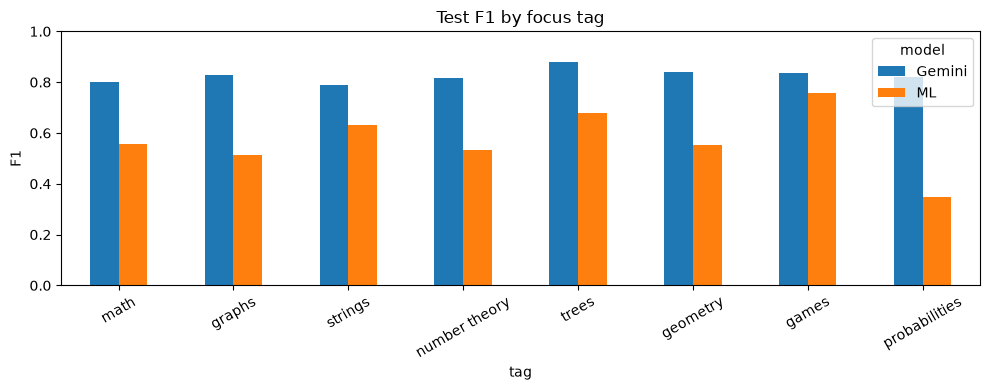

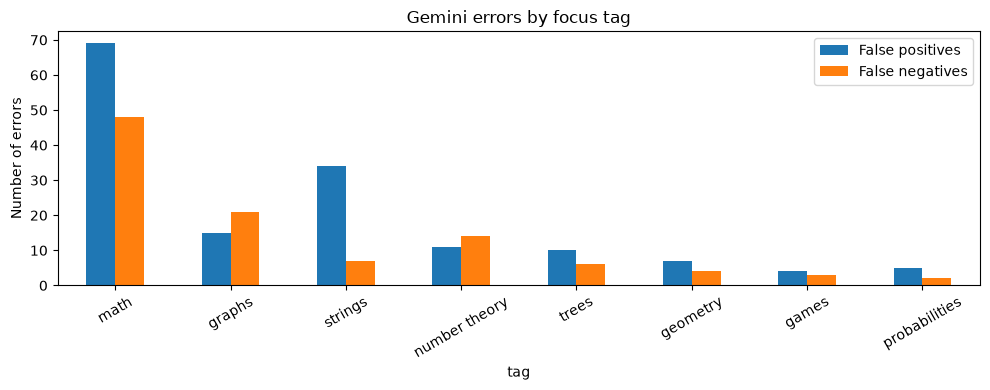

,id,tags,predicted,missing,extra
4553,4553,"[dfs and similar, dp, games, graphs, implement...","[bitmasks, dfs and similar, dp, graphs, trees]","[games, implementation, math, number theory, s...",[bitmasks]
3778,3778,"[brute force, combinatorics, constructive algo...","[combinatorics, geometry, math]","[brute force, constructive algorithms, dp, gra...",[]
3859,3859,"[bitmasks, data structures, implementation, ma...","[bitmasks, data structures, divide and conquer...","[implementation, math, sortings]","[divide and conquer, dp, greedy]"
3391,3391,"[data structures, constructive algorithms, bit...","[bitmasks, data structures, divide and conquer...",[constructive algorithms],"[divide and conquer, graphs, greedy, trees]"
4061,4061,"[brute force, data structures, dp, graphs, gre...","[dp, graphs, math]","[brute force, data structures, greedy, shortes...",[math]
2443,2443,"[dp, greedy, math, implementation, brute force]","[constructive algorithms, greedy]","[brute force, dp, implementation, math]",[constructive algorithms]
1247,1247,"[dp, greedy, constructive algorithms, bitmasks...","[bitmasks, dp, math]","[brute force, constructive algorithms, greedy,...",[math]
161,161,"[implementation, probabilities, math]","[brute force, greedy, probabilities, strings]","[implementation, math]","[brute force, greedy, strings]"
4615,4615,"[constructive algorithms, dfs and similar, geo...","[dfs and similar, geometry, graphs, greedy, math]","[constructive algorithms, sortings, trees]","[greedy, math]"
4598,4598,"[brute force, greedy, implementation]","[math, strings]","[brute force, greedy, implementation]","[math, strings]"


In [71]:
# 1. F1 comparison on focus tags
f1_plot = (
    tag_metrics[tag_metrics.tag.isin(FOCUS)]
    .pivot(index="tag", columns="model", values="F1")
    .loc[FOCUS]
)

ax = f1_plot.plot.bar(figsize=(10, 4), rot=30)
ax.set(ylabel="F1", title="Test F1 by focus tag", ylim=(0, 1))
plt.tight_layout()
plt.savefig(OUT / "reports/f1_by_tag.png", dpi=180)
plt.show()


# 2. Gemini false positives / false negatives by tag
fp = ((gemini_test_pred == 1) & (y_test == 0)).sum(axis=0)
fn = ((gemini_test_pred == 0) & (y_test == 1)).sum(axis=0)

error_counts = pd.DataFrame({
    "tag": TAGS, "False positives": fp, "False negatives": fn
}).set_index("tag").loc[FOCUS]

ax = error_counts.plot.bar(figsize=(10, 4), rot=30)
ax.set(ylabel="Number of errors", title="Gemini errors by focus tag")
plt.tight_layout()
plt.savefig(OUT / "reports/errors_by_tag.png", dpi=180)
plt.show()


# 3. Inspect worst Gemini predictions
errors = test[["id", "tags", "prob_desc_description"]].copy()

errors["predicted"] = [
    [TAGS[j] for j in np.flatnonzero(row)]
    for row in gemini_test_pred
]
errors["missing"] = [
    sorted(set(a) - set(b))
    for a, b in zip(errors.tags, errors.predicted)
]
errors["extra"] = [
    sorted(set(b) - set(a))
    for a, b in zip(errors.tags, errors.predicted)
]
errors["n_errors"] = errors.missing.map(len) + errors.extra.map(len)

display(
    errors.sort_values("n_errors", ascending=False)[
        ["id", "tags", "predicted", "missing", "extra"]
    ].head(10)
)

errors.to_csv(OUT / "reports/gemini_errors.csv", index=False)

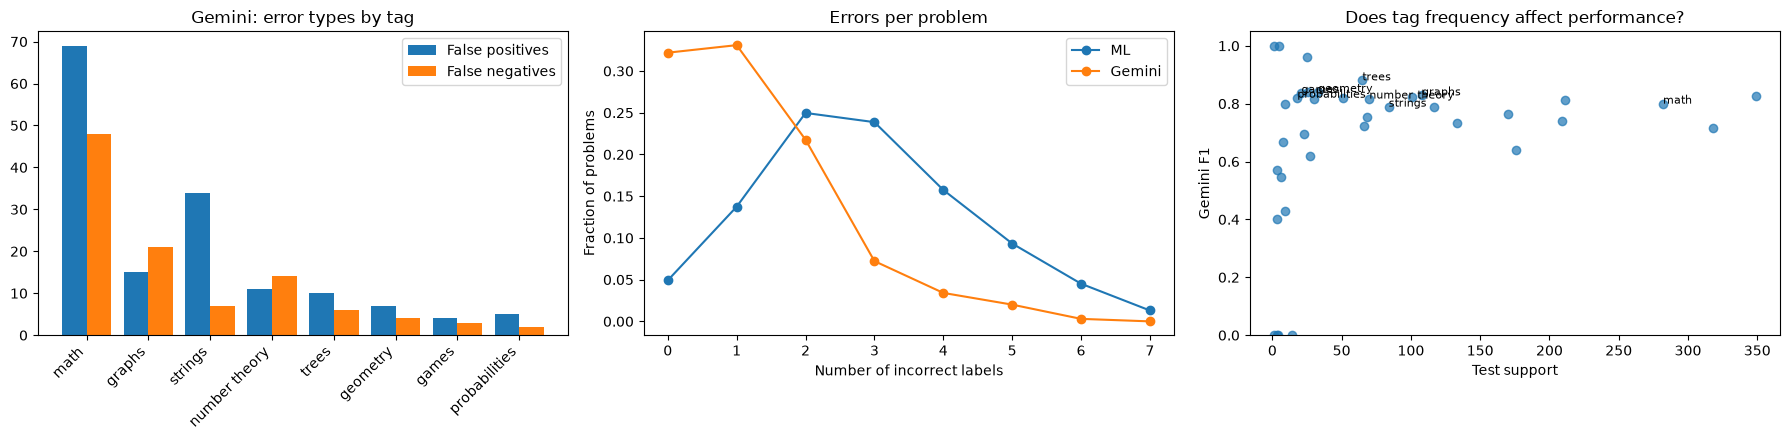

In [72]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

# 1. False positives vs false negatives
idx = [TAGS.index(t) for t in FOCUS]
fp = ((gemini_test_pred == 1) & (y_test == 0)).sum(axis=0)[idx]
fn = ((gemini_test_pred == 0) & (y_test == 1)).sum(axis=0)[idx]

x = np.arange(len(FOCUS))
axes[0].bar(x - .2, fp, .4, label="False positives")
axes[0].bar(x + .2, fn, .4, label="False negatives")
axes[0].set_xticks(x, FOCUS, rotation=45, ha="right")
axes[0].set_title("Gemini: error types by tag")
axes[0].legend()

# 2. Label cardinality errors
for pred, name in [(ml_test_pred, "ML"), (gemini_test_pred, "Gemini")]:
    errors_per_problem = np.abs(pred - y_test).sum(axis=1)
    counts = np.bincount(errors_per_problem, minlength=8)[:8]
    axes[1].plot(range(8), counts / len(y_test), marker="o", label=name)

axes[1].set_title("Errors per problem")
axes[1].set_xlabel("Number of incorrect labels")
axes[1].set_ylabel("Fraction of problems")
axes[1].legend()

# 3. Tag frequency vs Gemini F1
support = y_test.sum(axis=0)
f1 = f1_score(y_test, gemini_test_pred, average=None, zero_division=0)

axes[2].scatter(support, f1, alpha=.7)
for i in idx:
    axes[2].annotate(TAGS[i], (support[i], f1[i]), fontsize=8)

axes[2].set_title("Does tag frequency affect performance?")
axes[2].set_xlabel("Test support")
axes[2].set_ylabel("Gemini F1")
axes[2].set_ylim(0, 1.05)

plt.tight_layout()
plt.savefig(OUT / "reports/error_analysis.png", dpi=180)
plt.show()

## Conclusion

This study compared classical machine learning and large language model approaches for multilabel classification of Codeforces programming problems, with a primary focus on macro-F1 across eight priority tags.

**Classical ML.** TF-IDF and MiniLM embeddings achieved comparable standalone performance. Combining lexical and semantic representations through early fusion improved validation macro-F1 to **0.648**, demonstrating that the two feature spaces contain complementary information. However, the final ML model achieved approximately **0.57 macro-F1 on the held-out test set**, indicating a substantial generalization gap.

**LLM-based classification.** Gemini zero-shot substantially outperformed the classical baselines, achieving **0.827 macro-F1 across the eight priority tags** and **0.773 micro-F1 across all 37 tags** on the 997-problem test set. It performed better than the ML baseline on every priority tag. Fixed and retrieval-based few-shot prompting did not improve performance on the validation subset, suggesting that additional demonstrations were unnecessary for this task.

**Error analysis.** Despite its strong overall performance, Gemini still produces both missing and additional labels. Performance also varies across tags, highlighting the difficulty of multilabel classification when several algorithms or mathematical concepts may apply to the same problem.

**Operational considerations.** Gemini required approximately **7.1 seconds per API call** and **1,693 tokens per problem** on average. This introduces latency, API cost, and an external service dependency. In contrast, the classical ML approach is lightweight and can run locally.

**Limitations.** Codeforces problems are publicly available, so potential overlap with the LLM's pretraining data cannot be ruled out. In addition, performance was measured on one fixed train/validation/test split, and the few-shot comparison used a smaller validation subset.

**Final choice.** Gemini zero-shot was selected as the final inference approach because it delivered the strongest predictive performance while requiring no task-specific training. A separate Python CLI provides inference on new, unlabeled datasets using the same prompt and model configuration.